In [1]:
#202431055_Muhammad Rafi Kurniawan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

pd.set_option('display.max_columns', None)

In [2]:
#202431055_Muhammad Rafi Kurniawan
data = pd.read_csv('data.csv')
print('Ukuran data (baris, kolom):', data.shape)
data.head()

Ukuran data (baris, kolom): (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:
#202431055_Muhammad Rafi Kurniawan
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [4]:
#202431055_Muhammad Rafi Kurniawan
data.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [5]:
#202431055_Muhammad Rafi Kurniawan
print('Nilai kosong per kolom sebelum pembersihan (hanya kolom yang kosong):')
kosong_sebelum = data.isna().sum()
print(kosong_sebelum[kosong_sebelum > 0])

Nilai kosong per kolom sebelum pembersihan (hanya kolom yang kosong):
Unnamed: 32    569
dtype: int64


In [6]:
#202431055_Muhammad Rafi Kurniawan
data_bersih = data.drop(columns=['id', 'Unnamed: 32'])

print('Ukuran data sebelum :', data.shape)
print('Ukuran data sesudah :', data_bersih.shape)
print()
print('Total nilai kosong sesudah pembersihan:', data_bersih.isna().sum().sum())
print('Jumlah baris duplikat                  :', data_bersih.duplicated().sum())

Ukuran data sebelum : (569, 33)
Ukuran data sesudah : (569, 31)

Total nilai kosong sesudah pembersihan: 0
Jumlah baris duplikat                  : 0


In [7]:
#202431055_Muhammad Rafi Kurniawan

# 'B' = Benign    -> tumor Jinak (tidak ganas)
# 'M' = Malignant -> tumor Ganas (kanker)

print('Nilai unik target:', data_bersih['diagnosis'].unique())
print()
print('Jumlah tiap kelas:')
print(data_bersih['diagnosis'].value_counts())
print()
print('Persentase tiap kelas (%):')
print((data_bersih['diagnosis'].value_counts(normalize=True) * 100).round(2))

Nilai unik target: ['M' 'B']

Jumlah tiap kelas:
B    357
M    212
Name: diagnosis, dtype: int64

Persentase tiap kelas (%):
B    62.74
M    37.26
Name: diagnosis, dtype: float64


In [8]:
#202431055_Muhammad Rafi Kurniawan
le = LabelEncoder()
y_angka = le.fit_transform(data_bersih['diagnosis'])

print('le.classes_ :', le.classes_)
print()
print('Pemetaan kelas:')
for angka, nama in enumerate(le.classes_):
    print(f'  {nama} -> {angka}')

le.classes_ : ['B' 'M']

Pemetaan kelas:
  B -> 0
  M -> 1


In [9]:
#202431055_Muhammad Rafi Kurniawan
X = data_bersih.drop(columns=['diagnosis'])
y = pd.Series(y_angka, index=data_bersih.index, name='diagnosis')

X_latih, X_uji, y_latih, y_uji = train_test_split(X, y, test_size=0.3, random_state=0)

print('Jumlah fitur       :', X.shape[1])
print('Jumlah data latih  :', X_latih.shape[0])
print('Jumlah data uji    :', X_uji.shape[0])
print()

proporsi_latih = y_latih.value_counts(normalize=True).sort_index()
proporsi_uji = y_uji.value_counts(normalize=True).sort_index()
perbandingan = pd.DataFrame({'proporsi_latih': proporsi_latih, 'proporsi_uji': proporsi_uji}).round(4)
perbandingan.index = [f'{angka} ({nama})' for angka, nama in enumerate(le.classes_)]
print(perbandingan)

selisih = (proporsi_latih - proporsi_uji).abs().max()
print()
print(f'Selisih proporsi terbesar antara data latih dan uji: {selisih:.4f}')

Jumlah fitur       : 30
Jumlah data latih  : 398
Jumlah data uji    : 171

       proporsi_latih  proporsi_uji
0 (B)          0.6256        0.6316
1 (M)          0.3744        0.3684

Selisih proporsi terbesar antara data latih dan uji: 0.0060


In [10]:
#202431055_Muhammad Rafi Kurniawan
pipeline_svm = Pipeline([
    ('skaler', StandardScaler()),
    ('svc', SVC())
])
pipeline_svm

Pipeline(steps=[('skaler', StandardScaler()), ('svc', SVC())])

In [11]:
#202431055_Muhammad Rafi Kurniawan
grid_parameter = {
    'svc__kernel': ['linear', 'rbf', 'poly'],
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': ['scale', 0.01, 0.1, 1]
}

jumlah_kombinasi = 1
for nama_parameter, nilai in grid_parameter.items():
    jumlah_kombinasi *= len(nilai)

print('Jumlah kombinasi parameter :', jumlah_kombinasi, '(= 3 kernel x 4 nilai C x 4 nilai gamma)')
print('Jumlah pelatihan model     :', jumlah_kombinasi * 5, '(kombinasi x 5 lipatan validasi silang)')

Jumlah kombinasi parameter : 48 (= 3 kernel x 4 nilai C x 4 nilai gamma)
Jumlah pelatihan model     : 240 (kombinasi x 5 lipatan validasi silang)


In [12]:
#202431055_Muhammad Rafi Kurniawan
pencarian = GridSearchCV(
    estimator=pipeline_svm,
    param_grid=grid_parameter,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
pencarian.fit(X_latih, y_latih)

print('Parameter terbaik (versi GridSearchCV):')
print(pencarian.best_params_)
print(f'Skor validasi silang terbaik          : {pencarian.best_score_:.4f}')

Parameter terbaik (versi GridSearchCV):
{'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__kernel': 'linear'}
Skor validasi silang terbaik          : 0.9850


In [13]:
#202431055_Muhammad Rafi Kurniawan
hasil_cv = pd.DataFrame(pencarian.cv_results_)

kandidat_pertama = hasil_cv[hasil_cv['rank_test_score'] == 1][
    ['param_svc__kernel', 'param_svc__C', 'param_svc__gamma', 'mean_test_score', 'std_test_score']
].copy()
kandidat_pertama.columns = ['kernel', 'C', 'gamma', 'skor_rata_rata', 'simpangan_baku']

print('Jumlah kandidat peringkat 1:', len(kandidat_pertama))
kandidat_pertama

Jumlah kandidat peringkat 1: 4


,kernel,C,gamma,skor_rata_rata,simpangan_baku
0,linear,0.1,scale,0.985,0.014577
3,linear,0.1,0.01,0.985,0.014577
6,linear,0.1,0.1,0.985,0.014577
9,linear,0.1,1,0.985,0.014577


In [14]:
#202431055_Muhammad Rafi Kurniawan
urutan_kernel = {'linear': 0, 'rbf': 1, 'poly': 2}

kandidat_urut = kandidat_pertama.copy()
kandidat_urut['urutan_kernel'] = kandidat_urut['kernel'].map(urutan_kernel)
kandidat_urut['C'] = kandidat_urut['C'].astype(float)
kandidat_urut['simpangan_baku'] = kandidat_urut['simpangan_baku'].astype(float)
kandidat_urut = kandidat_urut.sort_values(['urutan_kernel', 'C', 'simpangan_baku'], kind='stable')

pilihan = kandidat_urut.iloc[0]
kernel_pilihan = pilihan['kernel']
C_pilihan = float(pilihan['C'])
gamma_pilihan = pilihan['gamma']

print('Model akhir yang dipilih:')
print('  kernel =', kernel_pilihan)
print('  C      =', C_pilihan)
print('  gamma  =', gamma_pilihan, '(tidak berpengaruh bila kernel linear)')

Model akhir yang dipilih:
  kernel = linear
  C      = 0.1
  gamma  = scale (tidak berpengaruh bila kernel linear)


In [15]:
#202431055_Muhammad Rafi Kurniawan
model_akhir = Pipeline([
    ('skaler', StandardScaler()),
    ('svc', SVC(kernel=kernel_pilihan, C=C_pilihan, gamma=gamma_pilihan))
])
model_akhir.fit(X_latih, y_latih)

prediksi_latih = model_akhir.predict(X_latih)
prediksi_uji = model_akhir.predict(X_uji)

akurasi_latih = accuracy_score(y_latih, prediksi_latih)
akurasi_uji = accuracy_score(y_uji, prediksi_uji)

print(f'Akurasi data latih : {akurasi_latih:.4f}')
print(f'Akurasi data uji   : {akurasi_uji:.4f}')
print(f'Selisih (latih - uji): {akurasi_latih - akurasi_uji:.4f}')

Akurasi data latih : 0.9874
Akurasi data uji   : 0.9708
Selisih (latih - uji): 0.0167


In [16]:
#202431055_Muhammad Rafi Kurniawan
nama_kelas = ['B (jinak)', 'M (ganas)']

for nama_data, label_asli, label_prediksi in [('DATA LATIH', y_latih, prediksi_latih),
                                              ('DATA UJI', y_uji, prediksi_uji)]:
    print('=' * 55)
    print(nama_data)
    print('=' * 55)
    matriks = confusion_matrix(label_asli, label_prediksi)
    print('Confusion matrix (baris = label asli, kolom = prediksi):')
    print(pd.DataFrame(matriks,
                       index=['Asli B (0)', 'Asli M (1)'],
                       columns=['Prediksi B (0)', 'Prediksi M (1)']))
    print()
    print('Classification report:')
    print(classification_report(label_asli, label_prediksi, target_names=nama_kelas, digits=4))

DATA LATIH
Confusion matrix (baris = label asli, kolom = prediksi):
            Prediksi B (0)  Prediksi M (1)
Asli B (0)             248               1
Asli M (1)               4             145

Classification report:
              precision    recall  f1-score   support

   B (jinak)     0.9841    0.9960    0.9900       249
   M (ganas)     0.9932    0.9732    0.9831       149

    accuracy                         0.9874       398
   macro avg     0.9886    0.9846    0.9865       398
weighted avg     0.9875    0.9874    0.9874       398

DATA UJI
Confusion matrix (baris = label asli, kolom = prediksi):
            Prediksi B (0)  Prediksi M (1)
Asli B (0)             106               2
Asli M (1)               3              60

Classification report:
              precision    recall  f1-score   support

   B (jinak)     0.9725    0.9815    0.9770       108
   M (ganas)     0.9677    0.9524    0.9600        63

    accuracy                         0.9708       171
   macro avg   

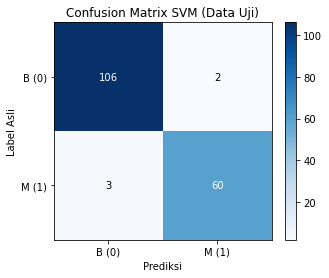

In [17]:
#202431055_Muhammad Rafi Kurniawan
matriks_uji = confusion_matrix(y_uji, prediksi_uji)

plt.figure(figsize=(5, 4))
plt.imshow(matriks_uji, cmap='Blues')
plt.title('Confusion Matrix SVM (Data Uji)')
plt.xlabel('Prediksi')
plt.ylabel('Label Asli')
plt.xticks([0, 1], ['B (0)', 'M (1)'])
plt.yticks([0, 1], ['B (0)', 'M (1)'])
for i in range(2):
    for j in range(2):
        plt.text(j, i, matriks_uji[i, j], ha='center', va='center',
                 color='white' if matriks_uji[i, j] > matriks_uji.max() / 2 else 'black')
plt.colorbar()
plt.show()

In [18]:
#202431055_Muhammad Rafi Kurniawan
fitur_2d = ['radius_mean', 'texture_mean']

print('Korelasi antar dua fitur terpilih:')
print(X_latih[fitur_2d].corr().round(4))

skaler_2d = StandardScaler().fit(X_latih[fitur_2d])
X_latih_2d = skaler_2d.transform(X_latih[fitur_2d])
X_uji_2d = skaler_2d.transform(X_uji[fitur_2d])

Korelasi antar dua fitur terpilih:
              radius_mean  texture_mean
radius_mean        1.0000        0.2952
texture_mean       0.2952        1.0000


In [19]:
#202431055_Muhammad Rafi Kurniawan
model_uji_pisah = SVC(kernel='linear', C=1000).fit(X_latih_2d, y_latih)
akurasi_hard = model_uji_pisah.score(X_latih_2d, y_latih)
print(f'Akurasi data latih dengan C = 1000: {akurasi_hard:.4f}')
print('Dapat dipisahkan sempurna?        :', 'Ya' if akurasi_hard == 1.0 else 'TIDAK (kelas saling tumpang tindih)')

Akurasi data latih dengan C = 1000: 0.8819
Dapat dipisahkan sempurna?        : TIDAK (kelas saling tumpang tindih)


In [20]:
#202431055_Muhammad Rafi Kurniawan
ringkasan_C = []
for C_coba in [0.1, 1, 10, 100]:
    model_coba = SVC(kernel='linear', C=C_coba).fit(X_latih_2d, y_latih)
    w_coba = model_coba.coef_[0]
    ringkasan_C.append({
        'C': C_coba,
        'margin (2/||w||)': 2 / np.linalg.norm(w_coba),
        'jumlah support vector': int(model_coba.n_support_.sum()),
        'akurasi latih': model_coba.score(X_latih_2d, y_latih),
        'akurasi uji': model_coba.score(X_uji_2d, y_uji)
    })
pd.DataFrame(ringkasan_C).round(4)

,C,margin (2/||w||),jumlah support vector,akurasi latih,akurasi uji
0,0.1,1.2142,144,0.8769,0.9006
1,1.0,0.8946,119,0.8794,0.9064
2,10.0,0.8595,114,0.8794,0.9064
3,100.0,0.8552,113,0.8819,0.9064


In [21]:
#202431055_Muhammad Rafi Kurniawan
C_2d = 1

model_2d = SVC(kernel='linear', C=C_2d)
model_2d.fit(X_latih_2d, y_latih)

w = model_2d.coef_[0]
b = model_2d.intercept_[0]
margin = 2 / np.linalg.norm(w)

print('coef_ (w)        :', model_2d.coef_)
print('intercept_ (b)   :', model_2d.intercept_)
print('n_support_       :', model_2d.n_support_, '-> [kelas B (0), kelas M (1)]')
print('Total support vector:', model_2d.n_support_.sum())
print()
print(f'||w||            : {np.linalg.norm(w):.4f}')
print(f'Margin = 2/||w|| : {margin:.4f}  (dalam satuan simpangan baku)')
print(f'Akurasi latih 2D : {model_2d.score(X_latih_2d, y_latih):.4f}')
print(f'Akurasi uji 2D   : {model_2d.score(X_uji_2d, y_uji):.4f}')

coef_ (w)        : [[2.16446129 0.55982472]]
intercept_ (b)   : [-0.48402458]
n_support_       : [59 60] -> [kelas B (0), kelas M (1)]
Total support vector: 119

||w||            : 2.2357
Margin = 2/||w|| : 0.8946  (dalam satuan simpangan baku)
Akurasi latih 2D : 0.8794
Akurasi uji 2D   : 0.9064


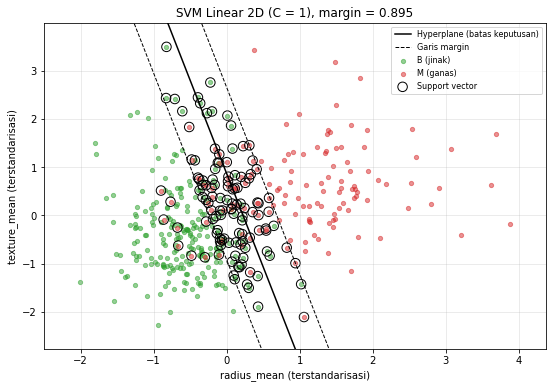

In [22]:
#202431055_Muhammad Rafi Kurniawan
plt.figure(figsize=(9, 6))

warna = {0: 'tab:green', 1: 'tab:red'}
label_kelas = {0: 'B (jinak)', 1: 'M (ganas)'}
for kelas in [0, 1]:
    plt.scatter(X_latih_2d[y_latih.values == kelas, 0], X_latih_2d[y_latih.values == kelas, 1],
                s=18, alpha=0.5, color=warna[kelas], label=label_kelas[kelas])

plt.scatter(model_2d.support_vectors_[:, 0], model_2d.support_vectors_[:, 1],
            s=90, facecolors='none', edgecolors='black', linewidths=1, label='Support vector')

x_garis = np.linspace(X_latih_2d[:, 0].min() - 0.5, X_latih_2d[:, 0].max() + 0.5, 200)
y_batas = -(w[0] * x_garis + b) / w[1]
y_margin_atas = -(w[0] * x_garis + b - 1) / w[1]
y_margin_bawah = -(w[0] * x_garis + b + 1) / w[1]

plt.plot(x_garis, y_batas, 'k-', label='Hyperplane (batas keputusan)')
plt.plot(x_garis, y_margin_atas, 'k--', linewidth=1, label='Garis margin')
plt.plot(x_garis, y_margin_bawah, 'k--', linewidth=1)

plt.xlim(X_latih_2d[:, 0].min() - 0.5, X_latih_2d[:, 0].max() + 0.5)
plt.ylim(X_latih_2d[:, 1].min() - 0.5, X_latih_2d[:, 1].max() + 0.5)
plt.title(f'SVM Linear 2D (C = {C_2d}), margin = {margin:.3f}')
plt.xlabel('radius_mean (terstandarisasi)')
plt.ylabel('texture_mean (terstandarisasi)')
plt.legend(loc='best', fontsize=8)
plt.grid(alpha=0.3)
plt.show()

In [23]:
#202431055_Muhammad Rafi Kurniawan
minimum_latih = X_latih.min()
maksimum_latih = X_latih.max()

semua_dalam_rentang = ((X_uji >= minimum_latih) & (X_uji <= maksimum_latih)).all(axis=1)

posisi = 0
baris_uji = X_uji.iloc[[posisi]]

dalam_rentang = (baris_uji.iloc[0] >= minimum_latih) & (baris_uji.iloc[0] <= maksimum_latih)
print(f'Baris data uji yang diambil (indeks asli {baris_uji.index[0]}):')
print('Semua fitur dalam rentang data latih?', bool(dalam_rentang.all()))

if not dalam_rentang.all():
    print('Fitur di luar rentang:', list(dalam_rentang[~dalam_rentang].index))
    # Pilih baris data uji pertama yang valid
    posisi = int(np.argmax(semua_dalam_rentang.values))
    baris_uji = X_uji.iloc[[posisi]]
    print(f'-> Diganti dengan baris data uji pertama yang valid (indeks asli {baris_uji.index[0]}).')

print()
print('Jumlah baris data uji yang valid (semua fitur dalam rentang):',
      int(semua_dalam_rentang.sum()), 'dari', len(X_uji))

Baris data uji yang diambil (indeks asli 512):
Semua fitur dalam rentang data latih? True

Jumlah baris data uji yang valid (semua fitur dalam rentang): 160 dari 171


In [24]:
#202431055_Muhammad Rafi Kurniawan
label_asli = y_uji.iloc[posisi]
prediksi_baru = model_akhir.predict(baris_uji)[0]
nilai_keputusan = model_akhir.decision_function(baris_uji)[0]

print('Label asli      :', label_asli, '->', le.inverse_transform([label_asli])[0])
print('Prediksi model  :', prediksi_baru, '->', le.inverse_transform([prediksi_baru])[0])
print(f'Nilai decision_function: {nilai_keputusan:.4f}  (positif -> kelas 1/M, negatif -> kelas 0/B)')
print('Prediksi benar? :', bool(label_asli == prediksi_baru))

Label asli      : 1 -> M
Prediksi model  : 1 -> M
Nilai decision_function: 2.2538  (positif -> kelas 1/M, negatif -> kelas 0/B)
Prediksi benar? : True
